# PDAC Incomplete_Cases — pan-cancer Hist2Pheno

195 unlabeled Pancreas TMA cores (no cell-type CSV) from **three coverslips** of Charvill-94 / s1167:

| Coverslip | Unlabeled cores | Role here |
|--|--:|--|
| **c003** | 19 | 3 largest (stroma-rich TMA) |
| **c005** | 95 | immune-high / stroma-high / mixed among large scored cores |
| **c007** | 81 | 3 largest (CD8 / epithelium / mixed) |

Each of the 9 cores: whole-core L1/L12/L2, then a mixed-class **HE zoom + Hist2Pheno zoom**. No TLS / SRI / TNI.

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

```bash
CUDA_DEVICE=0 bash code/External_val/PDAC_unlabel/demo.sh predict
# extra cores used below (c003 / c007) were scored with unlabeled_external.cmd_predict
```


In [1]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "External_val"))

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle

from Hist2Pheno_pkg.panel_figures import (
    crop_he_rectangle,
    nuclei_in_rectangle,
    plot_pred_composition_stacked,
    plot_roi_pred_spatial,
)

import unlabeled_external as ue

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

COHORT = "PDAC_unlabel"
SAVE_FIGURES = True
FIGSIZE = (17.2, 12.5)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 3.0
ZOOM_MARKER_PX = 5.5

cohort = ue._cohort(COHORT)
fig_dir = cohort.pred_parent / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
palettes = ue._palettes()
cov = ue.coverage(COHORT)
cov["coverslip"] = cov["sample"].map(ue.coverslip_of)
samples = ue.representative_pdac_samples()
print(
    f"{COHORT}: {len(cov)} unlabeled cores in {sorted(cov['coverslip'].unique())}; "
    f"showing {len(samples)} (3 per coverslip)"
)
display(cov.groupby("coverslip")[["feat", "pred", "he"]].sum())
display(cov.loc[cov["sample"].isin(samples)].sort_values(["coverslip", "n_feat_mb"], ascending=[True, False]))
missing = [s for s in samples if not ue.pred_h5ad(cohort, s).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing pred for: "
        + ", ".join(missing)
        + ". Run unlabeled_external.cmd_predict on representative_pdac_samples()."
    )


PDAC_unlabel: 195 unlabeled cores in ['c003', 'c005', 'c007']; showing 9 (3 per coverslip)


,feat,pred,he
coverslip,,,
c003,19,3,19
c005,95,5,95
c007,81,3,81


,sample,n_feat_mb,feat,pred,he,coverslip
25,Charvill-94_c003_v001_r001_reg146,55.45,True,True,True,c003
29,Charvill-94_c003_v001_r001_reg141,53.69,True,True,True,c003
31,Charvill-94_c003_v001_r001_reg147,53.12,True,True,True,c003
0,Charvill-94_c005_v001_r001_reg075,73.91,True,True,True,c005
3,Charvill-94_c005_v001_r001_reg047,66.54,True,True,True,c005
4,Charvill-94_c005_v001_r001_reg037,66.43,True,True,True,c005
7,Charvill-94_c007_v001_r001_reg062,62.82,True,True,True,c007
15,Charvill-94_c007_v001_r001_reg081,58.50,True,True,True,c007
16,Charvill-94_c007_v001_r001_reg069,58.33,True,True,True,c007


## Predicted composition (9 representative cores)


===== L1 =====


coverslip     c003                 c005                 c007              
core        reg141 reg146 reg147 reg037 reg047 reg075 reg062 reg069 reg081
class                                                                     
Endothelial  0.302  0.127  0.142  0.162  0.142  0.241  0.301  0.326  0.163
Epithelial   0.111  0.119  0.014  0.211  0.116  0.171  0.197  0.220  0.164
Immune       0.353  0.355  0.438  0.441  0.434  0.504  0.443  0.389  0.176
Stromal      0.234  0.399  0.406  0.186  0.308  0.084  0.059  0.065  0.497


===== L12 =====


coverslip     c003                 c005                 c007              
core        reg141 reg146 reg147 reg037 reg047 reg075 reg062 reg069 reg081
class                                                                     
B_Plasma     0.006  0.003  0.000  0.012  0.003  0.003  0.012  0.006  0.000
Endothelial  0.011  0.010  0.003  0.007  0.004  0.007  0.017  0.020  0.001
Epithelial   0.094  0.116  0.007  0.175  0.106  0.129  0.145  0.178  0.176
Myeloid      0.117  0.091  0.122  0.038  0.058  0.021  0.023  0.017  0.065
Stromal      0.238  0.363  0.228  0.174  0.254  0.062  0.064  0.063  0.417
T_cell       0.534  0.417  0.640  0.594  0.575  0.779  0.739  0.717  0.341


===== L2 =====


... (3 outputs left out)

/home/lingyu/ssd2/Python/Hist2Pheno/code/External_val/unlabeled_external.py:636: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/composition_L12.pdf


/home/lingyu/ssd2/Python/Hist2Pheno/code/External_val/unlabeled_external.py:636: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/composition_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/composition_L1.pdf


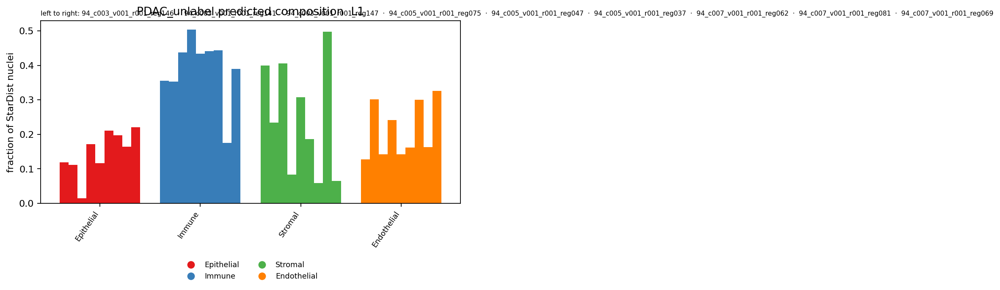

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/composition_L12.pdf


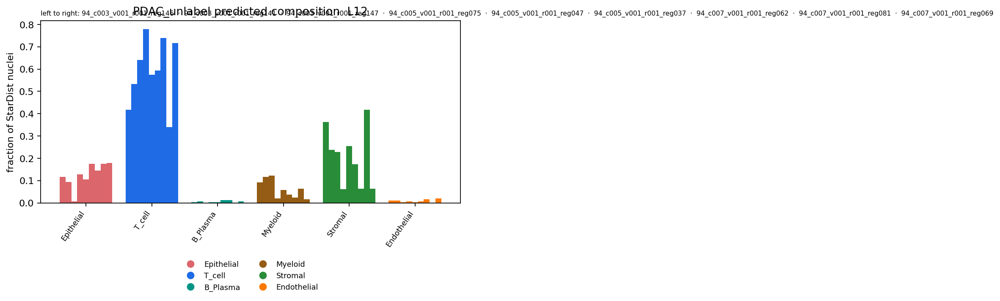

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/composition_L2.pdf


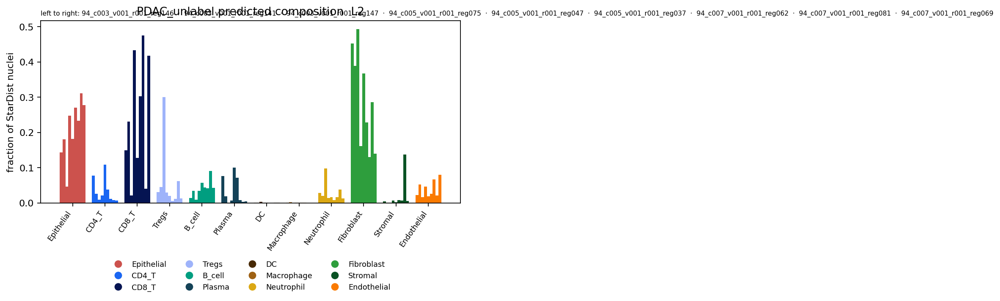

In [2]:
display(Markdown("## Predicted composition (9 representative cores)"))
comp = ue.composition_table(COHORT, samples)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    sub["coverslip"] = sub["sample"].map(ue.coverslip_of)
    sub["core"] = sub["sample"].str.replace(r".*reg", "reg", regex=True)
    wide = (
        sub.pivot_table(index="class", columns=["coverslip", "core"], values="fraction")
        .fillna(0.0)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))

for head, fig in zip(("L1", "L12", "L2"), ue.plot_composition(COHORT, samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)):
    if SAVE_FIGURES:
        mpl.rcParams["pdf.fonttype"] = 42
        mpl.rcParams["ps.fonttype"] = 42
        pdf = fig_dir / f"composition_{head}.pdf"
        fig.savefig(pdf, format="pdf", bbox_inches="tight", facecolor="white")
        print(pdf)
    display(fig)
    plt.close(fig)


## Whole-core maps and mixed-class zoom (3 cores × 3 coverslips)

### Coverslip c003

#### `Charvill-94_c003_v001_r001_reg146`  n=12,795  zoom [1486:2855]×[1520:2889]  nuclei=4,384

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg146_spatial_L1_L12_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg146_spatial_L1_L12_L2.pdf


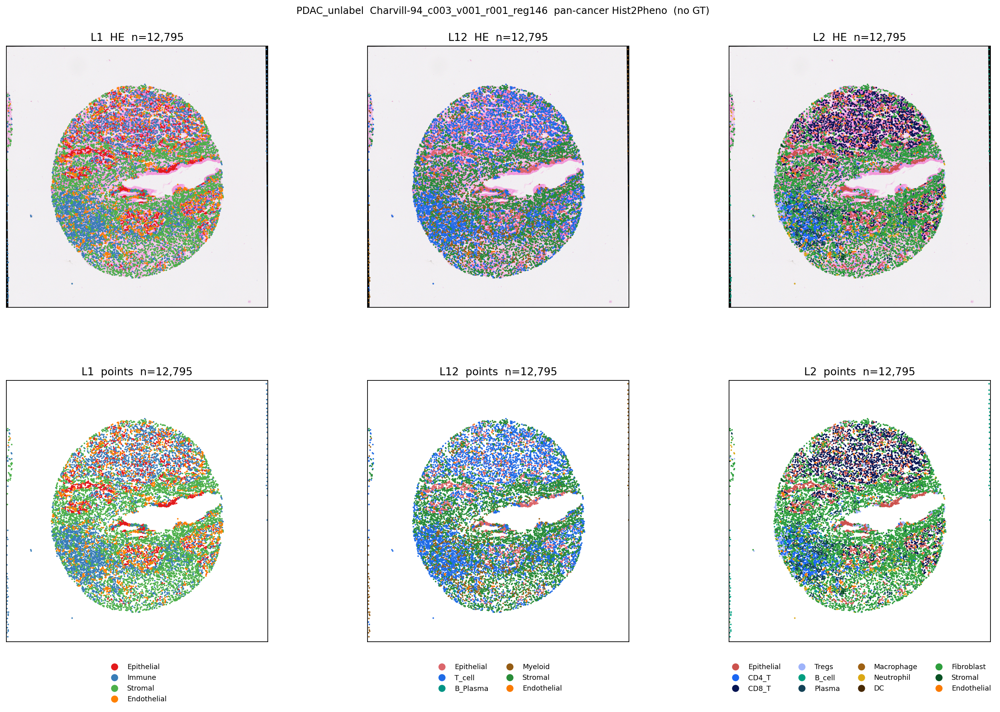

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg146_ROI_HE.pdf


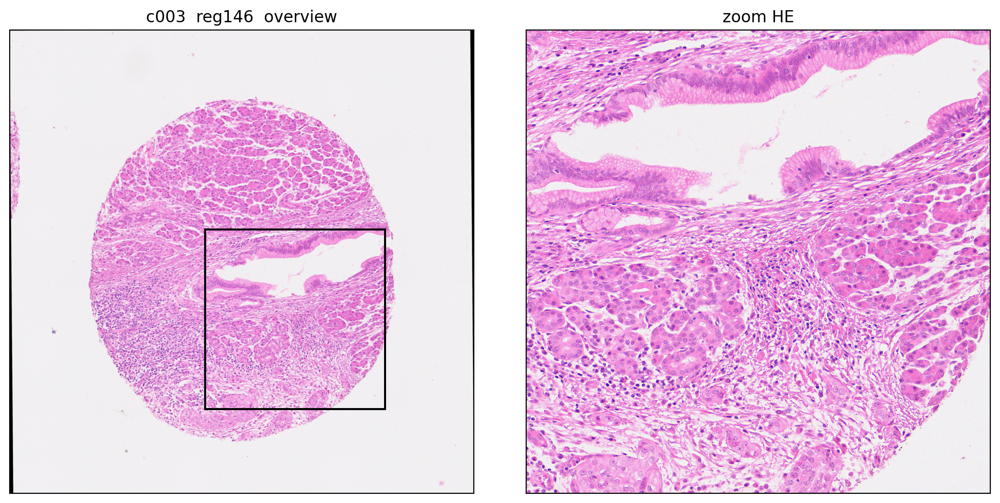

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg146_ROI_spatial_L1_L12_L2.pdf


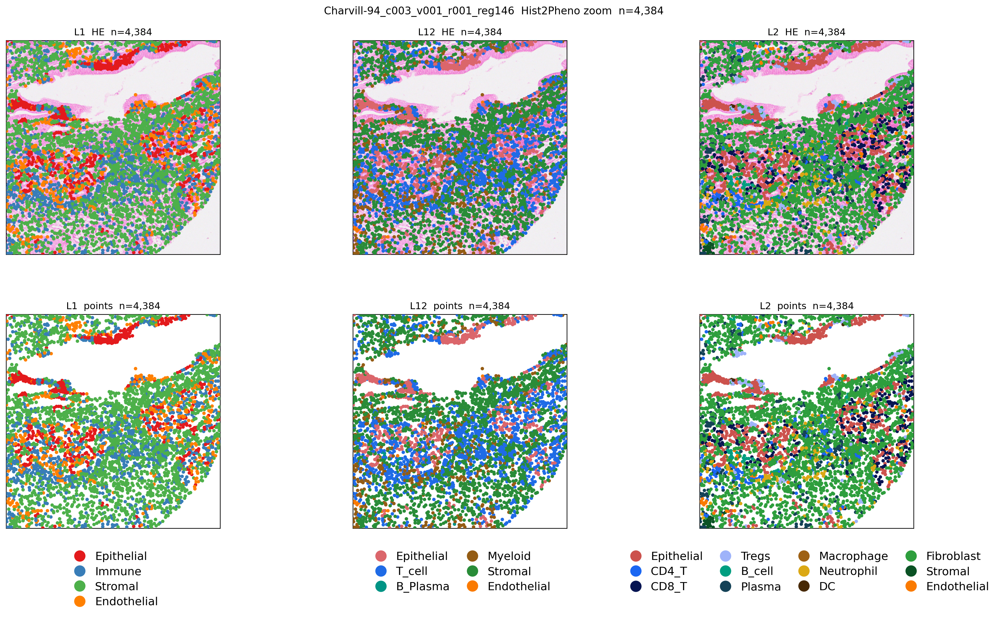

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg146_ROI_composition.pdf


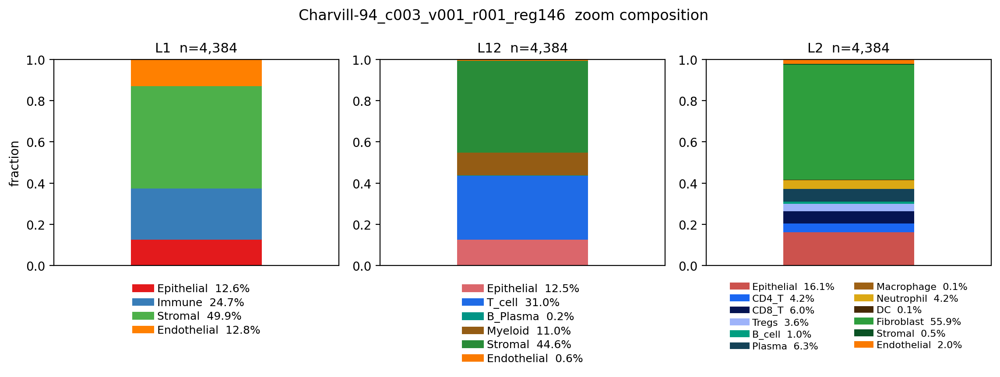

,head,class,n,fraction
0,L1,Epithelial,553,0.126
1,L1,Immune,1082,0.247
2,L1,Stromal,2186,0.499
3,L1,Endothelial,563,0.128
4,L12,Epithelial,550,0.125
5,L12,T_cell,1360,0.310
6,L12,B_Plasma,8,0.002
7,L12,Myeloid,481,0.110
8,L12,Stromal,1957,0.446
9,L12,Endothelial,28,0.006


#### `Charvill-94_c003_v001_r001_reg141`  n=12,388  zoom [514:1919]×[1525:2930]  nuclei=4,573

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg141_spatial_L1_L12_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg141_spatial_L1_L12_L2.pdf


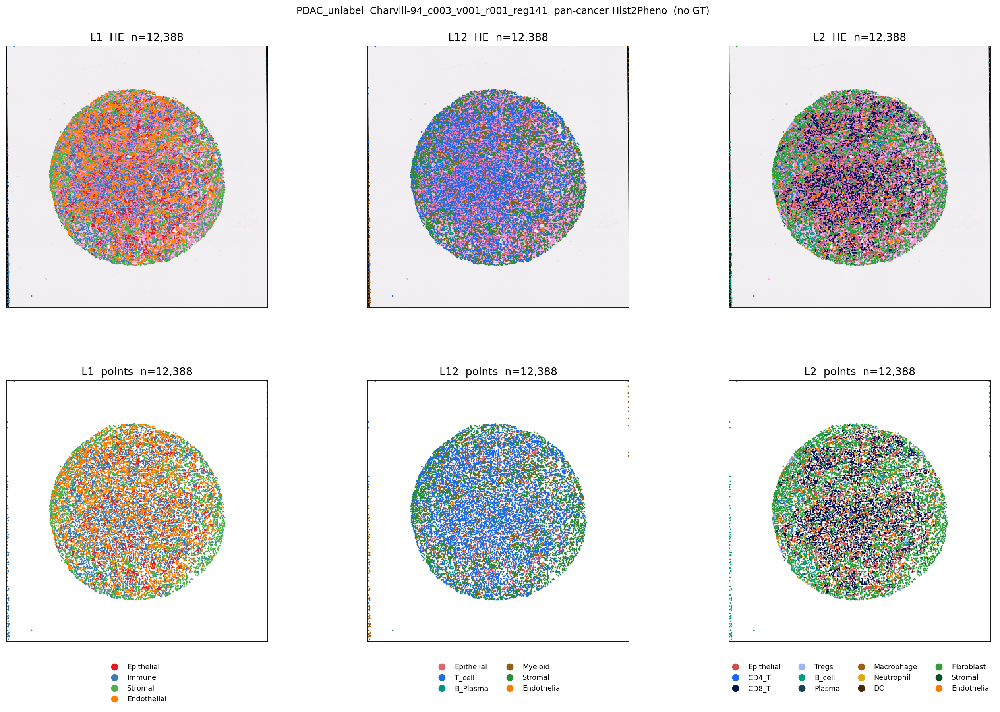

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg141_ROI_HE.pdf


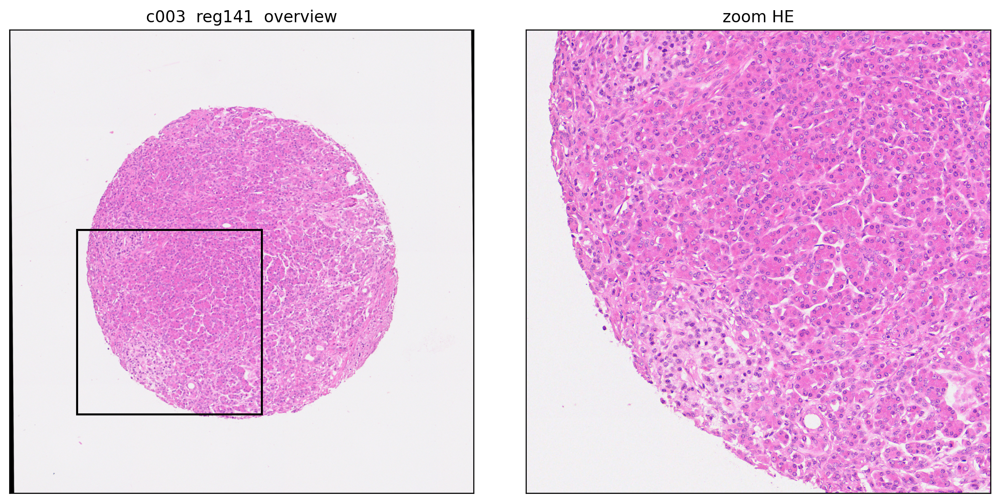

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg141_ROI_spatial_L1_L12_L2.pdf


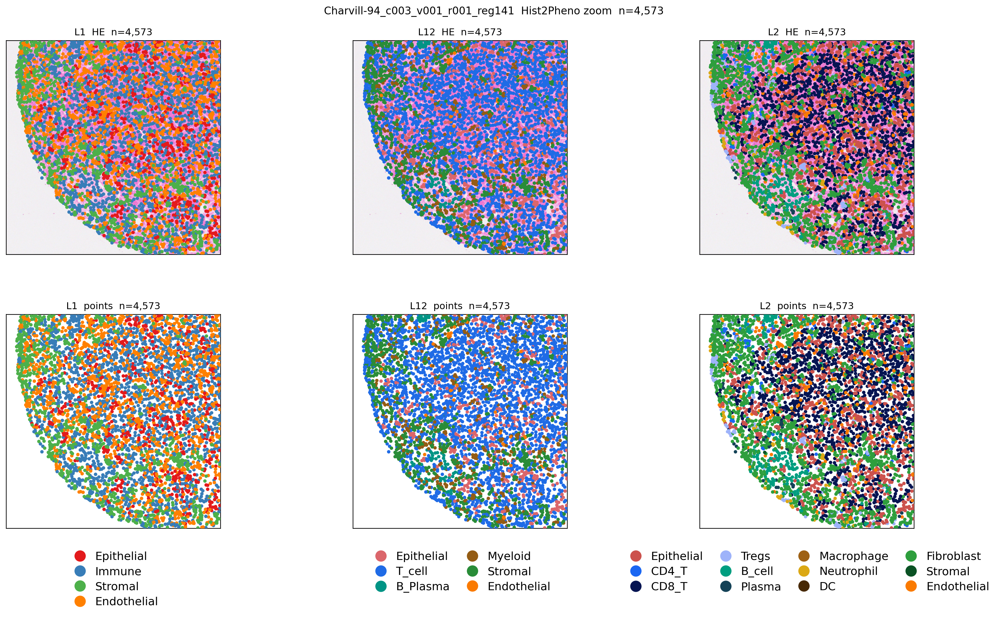

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg141_ROI_composition.pdf


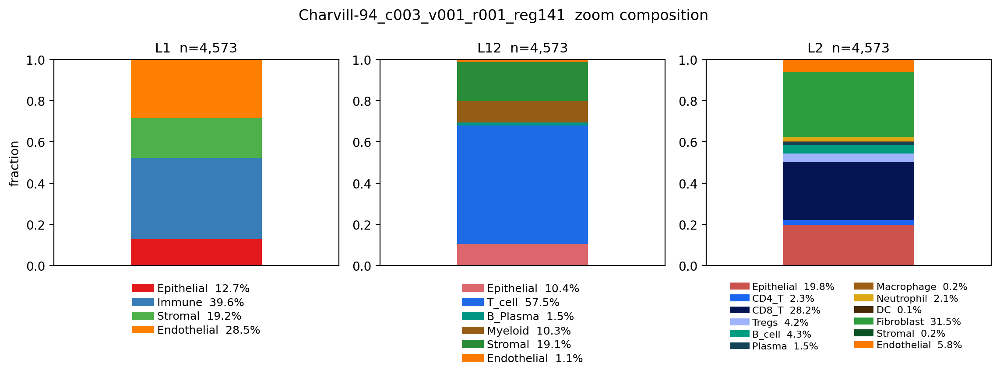

,head,class,n,fraction
0,L1,Epithelial,582,0.127
1,L1,Immune,1810,0.396
2,L1,Stromal,877,0.192
3,L1,Endothelial,1304,0.285
4,L12,Epithelial,476,0.104
5,L12,T_cell,2631,0.575
6,L12,B_Plasma,68,0.015
7,L12,Myeloid,473,0.103
8,L12,Stromal,873,0.191
9,L12,Endothelial,52,0.011


#### `Charvill-94_c003_v001_r001_reg147`  n=12,255  zoom [1017:2417]×[512:1913]  nuclei=5,588

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg147_spatial_L1_L12_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg147_spatial_L1_L12_L2.pdf


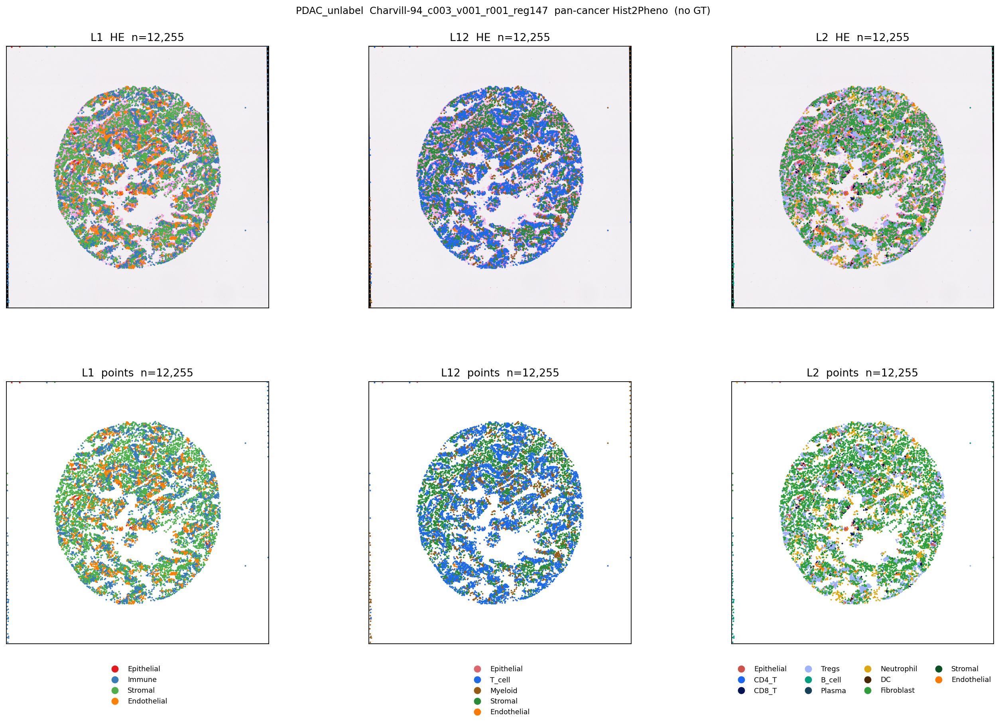

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg147_ROI_HE.pdf


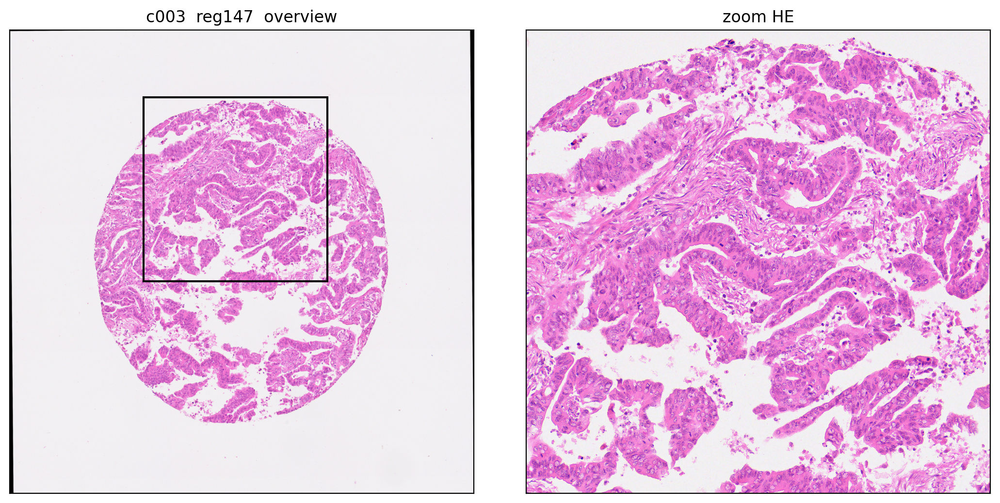

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg147_ROI_spatial_L1_L12_L2.pdf


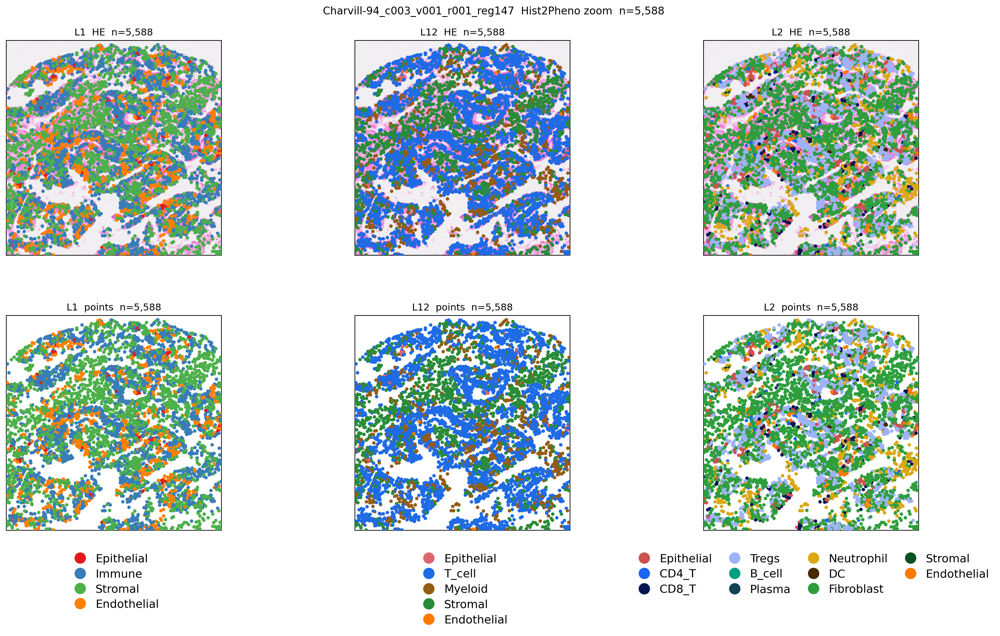

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c003_v001_r001_reg147_ROI_composition.pdf


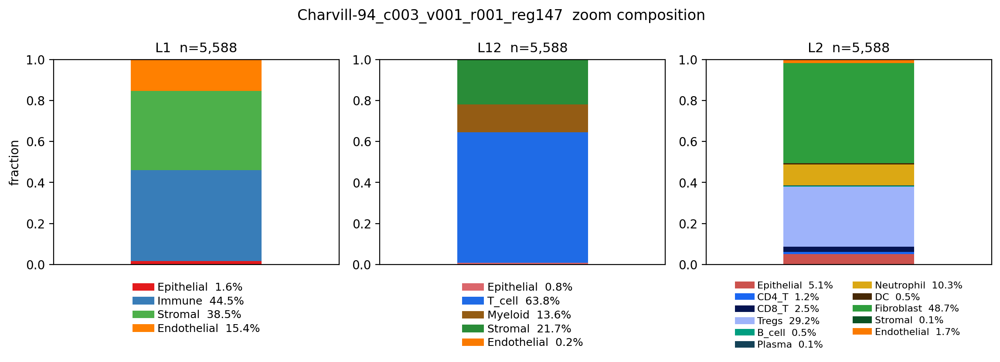

,head,class,n,fraction
0,L1,Epithelial,90,0.016
1,L1,Immune,2486,0.445
2,L1,Stromal,2151,0.385
3,L1,Endothelial,861,0.154
4,L12,Epithelial,46,0.008
5,L12,T_cell,3564,0.638
6,L12,Myeloid,759,0.136
7,L12,Stromal,1210,0.217
8,L12,Endothelial,9,0.002
9,L2,Epithelial,283,0.051


### Coverslip c005

#### `Charvill-94_c005_v001_r001_reg075`  n=17,061  zoom [295:1322]×[1501:2528]  nuclei=3,053

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg075_spatial_L1_L12_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg075_spatial_L1_L12_L2.pdf


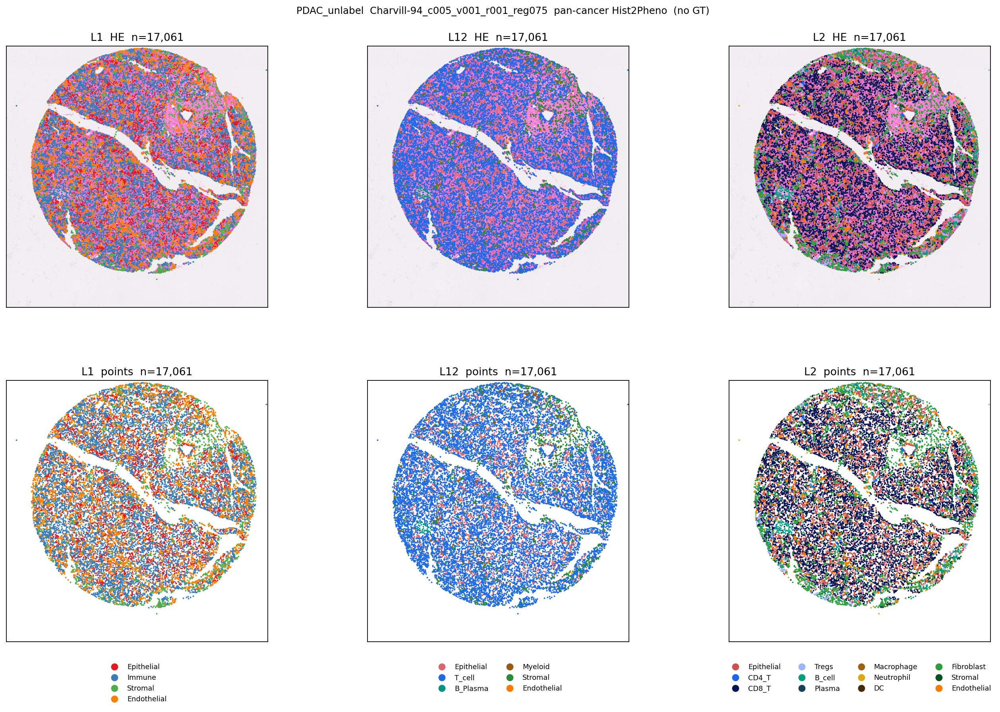

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg075_ROI_HE.pdf


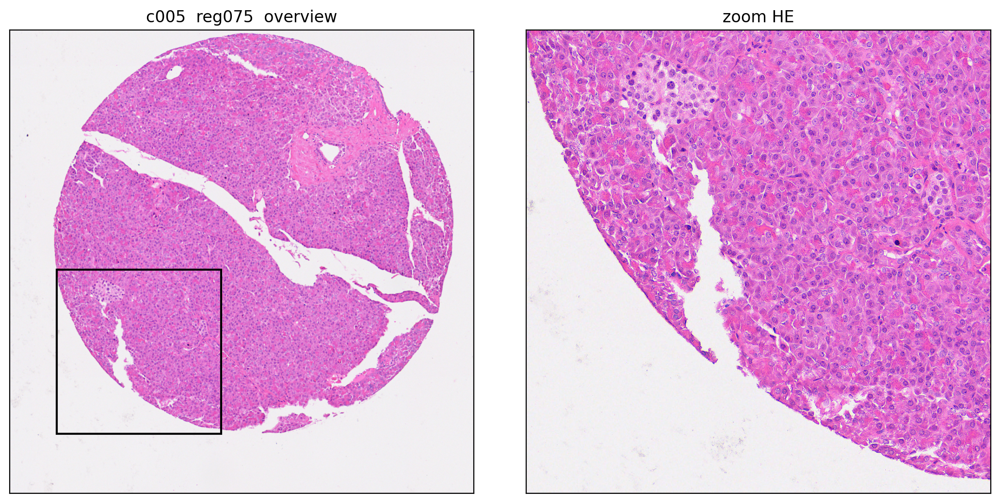

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg075_ROI_spatial_L1_L12_L2.pdf


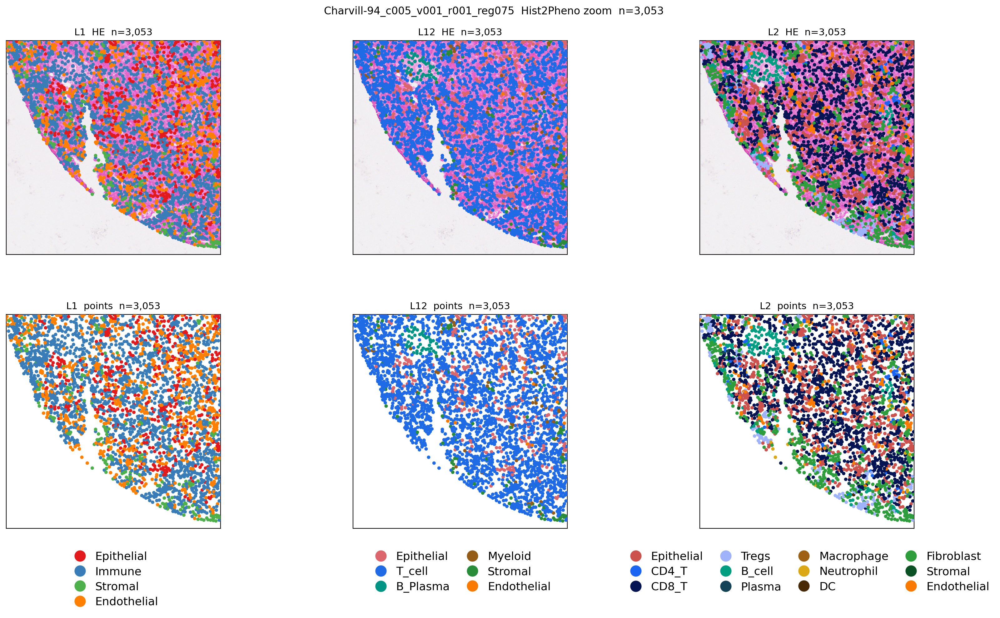

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg075_ROI_composition.pdf


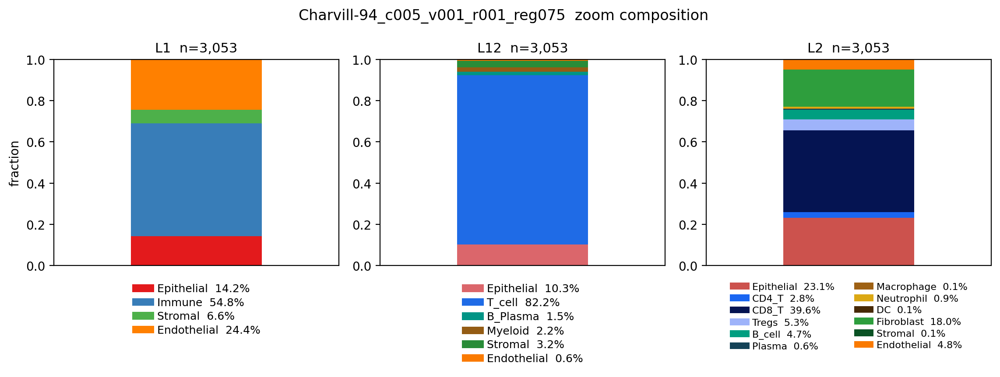

,head,class,n,fraction
0,L1,Epithelial,433,0.142
1,L1,Immune,1674,0.548
2,L1,Stromal,200,0.066
3,L1,Endothelial,746,0.244
4,L12,Epithelial,314,0.103
5,L12,T_cell,2509,0.822
6,L12,B_Plasma,46,0.015
7,L12,Myeloid,67,0.022
8,L12,Stromal,98,0.032
9,L12,Endothelial,19,0.006


#### `Charvill-94_c005_v001_r001_reg047`  n=15,360  zoom [244:1231]×[635:1622]  nuclei=2,892

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg047_spatial_L1_L12_L2.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_unlabel/PDAC_unlabel/figures/Charvill-94_c005_v001_r001_reg047_spatial_L1_L12_L2.pdf


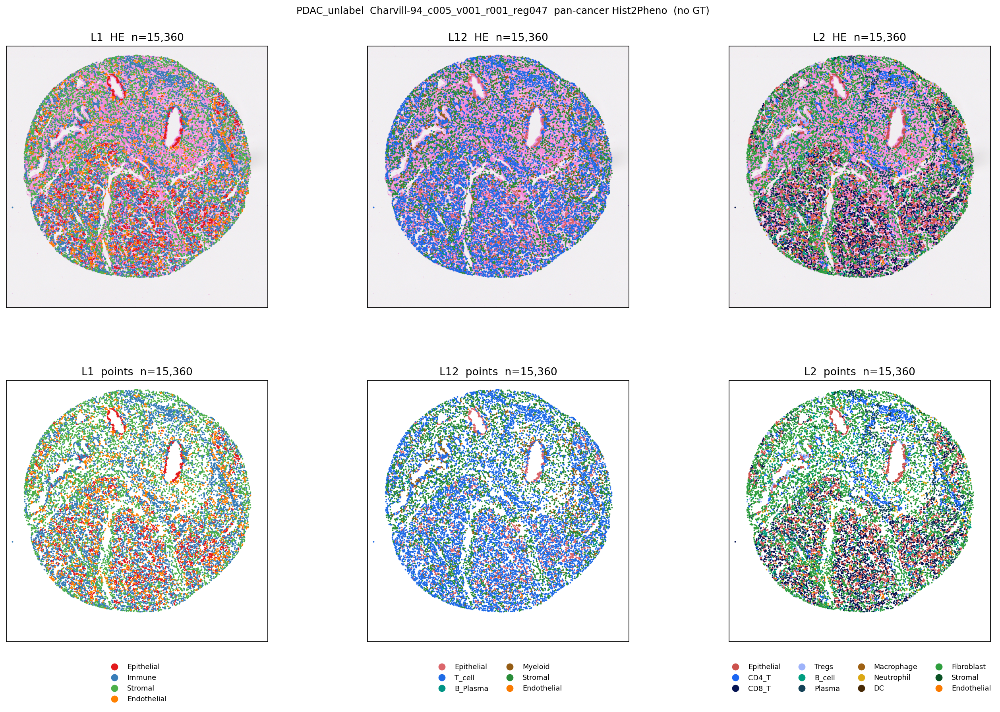

In [ ]:
display(Markdown("## Whole-core maps and mixed-class zoom (3 cores × 3 coverslips)"))

def save_both(fig, stem: Path):
    """PNG + Type 42 PDF (editable text). Does not change marker sizes."""
    if not SAVE_FIGURES:
        return
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig.savefig(stem.with_suffix(".png"), dpi=SAVE_DPI, bbox_inches="tight", facecolor="white")
    fig.savefig(stem.with_suffix(".pdf"), format="pdf", bbox_inches="tight", facecolor="white")
    print(stem.with_suffix(".pdf"))


for cs in ue.PDAC_COVERSLIPS:
    cores = list(ue.PDAC_REPRESENTATIVE[cs])
    display(Markdown(f"### Coverslip {cs}"))
    for sample in cores:
        pred_path = ue.pred_h5ad(cohort, sample)
        pred = ad.read_h5ad(pred_path)
        xy = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        l2 = pred.obs["pred_CT"].astype(str).to_numpy()
        he = ue.he_path(cohort, sample)
        x0, y0, x1, y1 = ue.mixed_rectangle_roi(xy, l2)
        in_roi = nuclei_in_rectangle(xy, x0, y0, x1, y1)
        display(Markdown(
            f"#### `{sample}`  n={pred.n_obs:,}  "
            f"zoom [{x0:.0f}:{x1:.0f}]×[{y0:.0f}:{y1:.0f}]  nuclei={int(in_roi.sum()):,}"
        ))

        figs = ue.plot_spatial(
            COHORT,
            [sample],
            save=SAVE_FIGURES,
            figsize=FIGSIZE,
            dpi=DPI,
            save_dpi=SAVE_DPI,
            he_max_side=HE_MAX_SIDE,
            marker_px=1.3*MARKER_PX,
        )
        for fig in figs:
            save_both(fig, fig_dir / f"{sample}_spatial_L1_L12_L2")
            display(fig)
            plt.close(fig)

        if he is None:
            print("no HE for", sample)
            continue
        thumb = ue._he_thumbnail(he, HE_MAX_SIDE)
        if thumb is None:
            print("HE thumbnail failed", sample)
            continue
        rgb, full_w, full_h = thumb
        he_file = he if he.is_file() else None
        fig_he, axes = plt.subplots(1, 2, figsize=(10.8, 5.2), dpi=max(int(DPI), 200))
        axes[0].imshow(rgb, extent=(0, full_w, full_h, 0), interpolation="bilinear")
        axes[0].add_patch(
            Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", lw=1.5)
        )
        axes[0].set_title(f"{cs}  {sample.split('_')[-1]}  overview")
        if he_file is not None:
            crop = crop_he_rectangle(he_file, x0, y0, x1, y1)
            axes[1].imshow(crop)
        else:
            axes[1].text(0.5, 0.5, "HE crop needs TIFF", ha="center")
        axes[1].set_title("zoom HE")
        for ax in axes:
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_aspect("equal")
        fig_he.tight_layout()
        save_both(fig_he, fig_dir / f"{sample}_ROI_HE")
        display(fig_he)
        plt.close(fig_he)

        if he_file is None:
            continue
        fig_z, _ = plot_roi_pred_spatial(
            pred,
            he_file,
            x0=x0,
            y0=y0,
            x1=x1,
            y1=y1,
            palettes=palettes,
            in_roi=in_roi,
            marker_px=2*ZOOM_MARKER_PX,
            dpi=max(int(DPI), 200),
            figsize=(16.8, 11.0),
            title=f"{sample}  Hist2Pheno zoom  n={int(in_roi.sum()):,}",
            save_path=None,
            save_dpi=SAVE_DPI,
        )
        save_both(fig_z, fig_dir / f"{sample}_ROI_spatial_L1_L12_L2")
        display(fig_z)
        plt.close(fig_z)

        fig_bar, tab = plot_pred_composition_stacked(
            pred.obs.loc[in_roi],
            palettes,
            dpi=max(int(DPI), 200),
            figsize=(11.6, 4.2),
            title=f"{sample}  zoom composition",
            save_path=None,
        )
        save_both(fig_bar, fig_dir / f"{sample}_ROI_composition")
        display(fig_bar)
        plt.close(fig_bar)
        display(tab.round(3))
